# 3. Live Stream Analysis: Analyze Sample ADARA File using Command Line Interface (CLI)

This tutorial shows how to run the `live_stream_analysis analyze` sub-command using the command-line interface (CLI) with the sample data provided by a recorded ADARA file.

A recorded ADARA file holds the same packets the beamline's stream management service (SMS) sends
live, saved to disk. Unlike NeXus, ADARA carries true per-pulse timing and proton
charge in its RTDL packets, so the error-decay series here is measured, not attributed.

The tutorial file holds the first 40 pulses (0.67 s) of diamond run 244114, closed by the run's
`END_RUN` packet, so the analyzer sees one complete run.

The full run is recorded as 16 files of about 210 MB each, and only the last carries `END_RUN`.
`--adara-file` reads one file; to replay a whole run, use the stream notebooks
(`04_analyze_adara_stream_*`).

**Before you start:** run `01_preparer_cli.ipynb` or `01_preparer_python.ipynb` once. They write the
pixel geometry, background and normalization CSVs into `notebooks/output/` that every analyze
notebook reads.

**Runtime:** seconds on the tutorial file. One full-run file takes about a minute, and up to 6
minutes the first time it is read over the NFS share, since the reading is I/O bound.

## Setup

This cell checks that the environment running this notebook has `live_stream_analysis` installed and its command on
`PATH`, then moves to the repository root, so every path below is the one you would type in a terminal
there.

If it fails, follow "Installing" in `notebooks/README.md`.

In [1]:
import os
import sys
from pathlib import Path

# The walkthrough needs live_stream_analysis installed in the environment this kernel runs in.
try:
    import live_stream_analysis
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        f"live_stream_analysis is not installed for this kernel ({sys.executable}). Follow "
        "'Installing' in notebooks/README.md, then start Jupyter from that environment."
    ) from error
print(f"live_stream_analysis {live_stream_analysis.__version__} on Python {sys.version.split()[0]}: {sys.executable}")

# The shell cells run the `live_stream_analysis` command, so it must be on PATH as well.
import shutil

command = shutil.which("live_stream_analysis")
if command is None:
    raise RuntimeError(
        "The live_stream_analysis command is not on PATH. Start Jupyter from the environment you "
        "installed it in, with that environment activated (see 'Installing' in notebooks/README.md)."
    )
print(f"live_stream_analysis command: {command}")

# Every path below is relative to the repository root, as it would be in a terminal there.
REPO_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents] if (path / "tests/data/tutorial").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from a clone of the live_stream_analysis repository.")
os.chdir(REPO_ROOT)
OUTPUT_DIR = Path("notebooks/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Working directory: {Path.cwd()}")
print(f"Output directory: {OUTPUT_DIR.absolute()}")
# True: show the live plot inside this notebook. False: open it in a browser tab instead.
LIVE_PLOT_INLINE = True

for prepared in ["pixel_geometry_calibrated.csv", "background.csv", "normalization.csv", "diamond_reflections.csv"]:
    if not (OUTPUT_DIR / prepared).exists():
        raise FileNotFoundError(f"{OUTPUT_DIR / prepared} is missing; run a 01_preparer notebook first")

live_stream_analysis 0.2.0 on Python 3.12.3: /home/ntm/projects/illumine/live_stream_analysis/.venv/bin/python3
live_stream_analysis command: /home/ntm/projects/illumine/live_stream_analysis/.venv/bin/live_stream_analysis
Working directory: /home/ntm/projects/illumine/live_stream_analysis
Output directory: /home/ntm/projects/illumine/live_stream_analysis/notebooks/output


## The command

Written as you would type it in a terminal; the backslashes are line continuations. For the full
run's first file, use `--adara-file path/to/adara/file/m00000001-f00000001-run-244114.adara`, refresh
every 200 packets, and drop `--statistics-sample-interval-seconds`.

| Option | Why |
| --- | --- |
| `--adara-file` | One recorded ADARA file |
| `--live-plot-refresh-every 20` | Refresh every 20 packets; the tutorial file has 678 |
| `--histogram-pixel-geometry-csv` | Per-pixel TOF→Q constants from the preparer, here with the 2026-06-09 calibration applied |
| `--histogram-q-min/-max/-bin-size` | 0–40 1/Å in 0.02 bins, the same binning the preparer used for background and vanadium |
| `--tof-tick-us 0.1` | ADARA event TOF is in 100 ns ticks. Checked on run 244114: with 0.1 the histogram overlays the same run's NeXus histogram, with diamond peak centres within 0.0015 1/Å of it; with 1.0 every peak sits at a tenth of its Q |
| `--background-subtraction`, `--normalization` | The empty-can and vanadium CSVs from the preparer |
| `--normalize-by proton-charge` | The default, spelled out: sample, background and vanadium are each divided by their own charge |
| `--histogram-output-csv` | The corrected I(Q) |
| `--statistics-output-csv`, `--statistics-q-min/-max` | The error-decay series, over the 2–18 1/Å range where diamond has its strong reflections |
| `--statistics-sample-interval-seconds 0.02` | The tutorial run lasts 0.67 s, so the decay series samples every 0.02 s rather than the default 1 s |
| `--live-plot-*` | Browser plot on a fixed port, kept open after the analysis, without opening a browser tab |

In [2]:
COMMAND = r"""
live_stream_analysis analyze \
    --adara-file tests/data/tutorial/m00000001-f00000001-run-244114.adara \
    --histogram-pixel-geometry-csv notebooks/output/pixel_geometry_calibrated.csv \
    --histogram-q-min 0.0 \
    --histogram-q-max 40.0 \
    --histogram-q-bin-size 0.02 \
    --tof-tick-us 0.1 \
    --background-subtraction notebooks/output/background.csv \
    --normalization notebooks/output/normalization.csv \
    --normalize-by proton-charge \
    --histogram-output-csv notebooks/output/adara_file_cli_iq.csv \
    --statistics-output-csv notebooks/output/adara_file_cli_statistics.csv \
    --statistics-q-min 2.0 \
    --statistics-q-max 18.0 \
    --statistics-sample-interval-seconds 0.02 \
    --live-plot-mode browser \
    --live-plot-port 8802 \
    --live-plot-no-open-browser \
    --live-plot-keep-open \
    --live-plot-refresh-every 20 \
    --event-log-interval 10000000
"""

## Run it

`run_command` starts that exact command as a background process, so the cell returns right away and
the live plot can be shown below. Its output goes to the log file.

In [3]:
from live_stream_analysis.notebook import run_command

run = run_command(COMMAND, log_file=OUTPUT_DIR / "adara_file_cli.log")
run

<AnalysisRun running url=http://127.0.0.1:8802/ log=/home/ntm/projects/illumine/live_stream_analysis/notebooks/output/adara_file_cli.log>

### How the live plot gets into the notebook

`live_plot_mode browser` makes the analyzer serve its plot page from a small HTTP server on its own
thread, and the page polls that server twice a second. Because the page talks to the analyzer and
not to the notebook kernel, it can sit in a cell output and keep updating while the kernel does
other things. The analysis therefore runs as a background process, and `show()` embeds the page
once the server is up.

`--live-plot-keep-open` keeps the page up after the analysis finishes, showing **Analysis complete**,
until you call `stop()`. Set `LIVE_PLOT_INLINE = False` above to open the same page in a browser
tab instead. The page loads Chart.js from a CDN, so it needs internet access.

In [4]:
if LIVE_PLOT_INLINE:
    run.show()
else:
    import webbrowser

    run.wait_for_plot()
    webbrowser.open(run.url)
    print(f"Live plot opened at {run.url}")

In [5]:
import time

# Re-run this cell any time for a progress snapshot; the analysis keeps going in the background.
deadline = time.monotonic() + 120
while run.plot_state()["status"]["update_count"] == 0 and time.monotonic() < deadline:
    time.sleep(2)
status = run.plot_state()["status"]
print(
    f"updates={status['update_count']}  elapsed={status['elapsed_seconds']:.1f} s  "
    f"charge={status['proton_charge_pc']:.3g} pC  mean sigma/I={status['mean_relative_uncertainty']:.4f}"
)

updates=1  elapsed=0.0 s  charge=0 pC  mean sigma/I=0.0000


## Wait for it to finish

The live plot keeps updating above while this cell waits.

In [6]:
run.wait()
print(run.log(22))

2026-10-26 15:00:51,043 INFO live_stream_analysis.analyzer.histogram_runner: Background CSV exposure totals: CorrectionTotals(proton_charge_pc=3473296320.0, duration_s=2.5)
2026-10-26 15:00:51,043 INFO live_stream_analysis.analyzer.histogram_runner: Normalization enabled: /home/ntm/projects/illumine/live_stream_analysis/notebooks/output/normalization.csv
2026-10-26 15:00:51,043 INFO live_stream_analysis.analyzer.histogram_runner: Normalization CSV exposure totals: CorrectionTotals(proton_charge_pc=693417800.0, duration_s=0.5)
2026-10-26 15:00:51,052 INFO live_stream_analysis.analyzer.histogram_runner: Histogram CSV output will be written to /home/ntm/projects/illumine/live_stream_analysis/notebooks/output/adara_file_cli_iq.csv
2026-10-26 15:00:51,052 INFO live_stream_analysis.analyzer.histogram_runner: Live plot mode: browser
2026-10-26 15:00:51,052 INFO live_stream_analysis.analyzer.histogram_runner: Event progress log interval set to 10000000 histogrammed events
Browser live plot ava

## Results

The corrected I(Q) is background-subtracted and vanadium-normalized, with sample, background and
vanadium each divided by their own proton charge. Dashed lines mark the expected diamond
reflections (a = 3.56712 Å), as an absolute check on the Q axis. The right panel is the error-decay
series the INTERSECT forecasting service consumes: for counting statistics, the mean σ/I(Q) should
fall as 1/√charge.

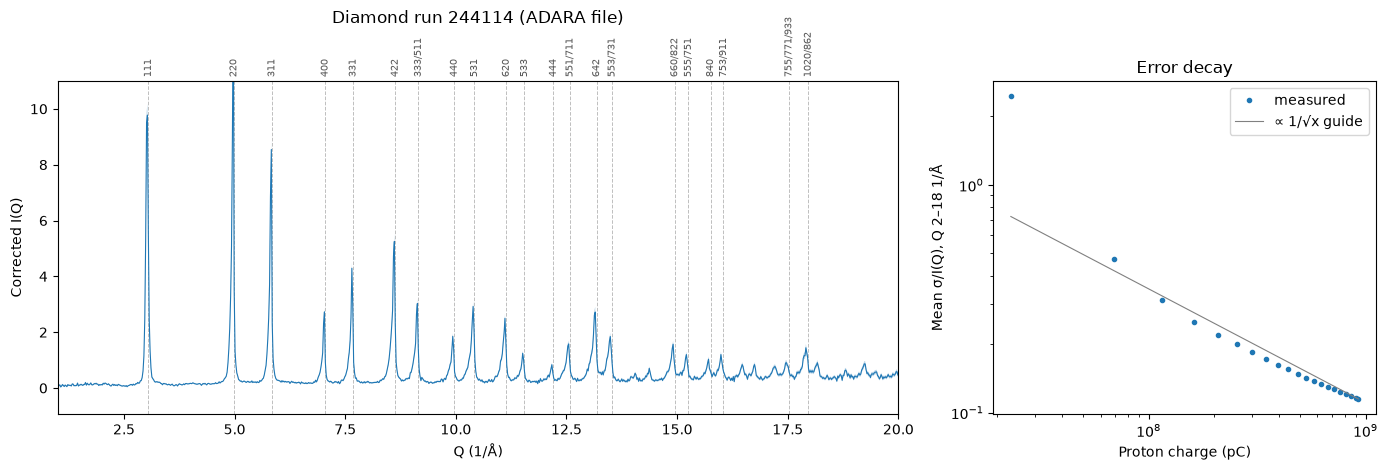

21 decay samples; final mean sigma/I = 0.1149 at 9.257e+08 (Proton charge (pC))


In [7]:
import matplotlib.pyplot as plt
import numpy as np

from live_stream_analysis.notebook import read_csv

iq = read_csv(OUTPUT_DIR / "adara_file_cli_iq.csv")
statistics = read_csv(OUTPUT_DIR / "adara_file_cli_statistics.csv")
reflections = read_csv(OUTPUT_DIR / "diamond_reflections.csv")

q, intensity, error = iq["Q value"], iq["I(Q)"], iq["Error I(Q)"]
window = (q > 1.0) & (q < 20.0)
low, high = np.nanpercentile(intensity[window], [0.5, 99.9])

fig, (ax_iq, ax_decay) = plt.subplots(1, 2, figsize=(14, 4.8), width_ratios=[2.2, 1])
# Expected diamond reflections, labelled by hkl along the top.
shown = (reflections["rel intensity"] > 0.5) & (reflections["Q (1/A)"] < 20.0)
for q_peak, hkl in zip(reflections["Q (1/A)"][shown], reflections["hkl"][shown]):
    ax_iq.axvline(q_peak, color="0.75", linestyle="--", linewidth=0.7, zorder=0)
    ax_iq.annotate(
        hkl, xy=(q_peak, 1.0), xycoords=("data", "axes fraction"), xytext=(0, 3), textcoords="offset points",
        rotation=90, ha="center", va="bottom", fontsize=7, color="0.35",
    )
ax_iq.fill_between(q, intensity - error, intensity + error, alpha=0.3, linewidth=0)
ax_iq.plot(q, intensity, linewidth=0.8)
ax_iq.set(
    xlim=(1.0, 20.0),
    ylim=(low - 0.1 * (high - low), high + 0.1 * (high - low)),
    xlabel="Q (1/Å)",
    ylabel="Corrected I(Q)",
)
ax_iq.set_title("Diamond run 244114 (ADARA file)", pad=42)

charge = statistics["Proton charge (pC)"]
x_values, x_label = (charge, "Proton charge (pC)") if np.nanmax(charge) > 0 else (statistics["Elapsed time (s)"], "Elapsed time (s)")
sigma = statistics["Mean sigma/I(Q)"]
measured = x_values > 0  # the first sample can land before any charge or time has accrued
x_values, sigma = x_values[measured], sigma[measured]
ax_decay.loglog(x_values, sigma, marker=".", linestyle="none", label="measured")
# Anchored on the last, best-determined sample; the earliest ones carry almost no counts.
ax_decay.loglog(x_values, sigma[-1] * np.sqrt(x_values[-1] / x_values), color="0.5", linewidth=0.8, label="∝ 1/√x guide")
ax_decay.set(xlabel=x_label, ylabel="Mean σ/I(Q), Q 2–18 1/Å", title="Error decay")
ax_decay.legend()
fig.tight_layout()
plt.show()

print(f"{len(sigma)} decay samples; final mean sigma/I = {sigma[-1]:.4f} at {x_values[-1]:.4g} ({x_label})")

## Stop

`stop()` interrupts the analyzer as Ctrl-C would and shuts down the plot server. Everything above
was already written to `notebooks/output/`, so nothing is lost.

In [8]:
print(f"Analyzer exit code {run.stop()} (130 means it was interrupted, as intended)")

Analyzer exit code 130 (130 means it was interrupted, as intended)


## Running it without the notebook

Paste `COMMAND` into a terminal at the repository root. The analyzer prints
`Browser live plot available at http://127.0.0.1:8802/`; open that URL, and press Ctrl-C when you
are done with the plot. Drop `--live-plot-no-open-browser` to have it open the tab for you, or drop
`--live-plot-keep-open` to have the process exit as soon as the analysis is done.

Why not `!live_stream_analysis analyze ...` in a cell? It would work, but it blocks the kernel until
the analysis ends, so you could watch the plot only in a separate browser tab.